# EDA

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("insurance.csv")

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.shape

(1338, 7)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [6]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

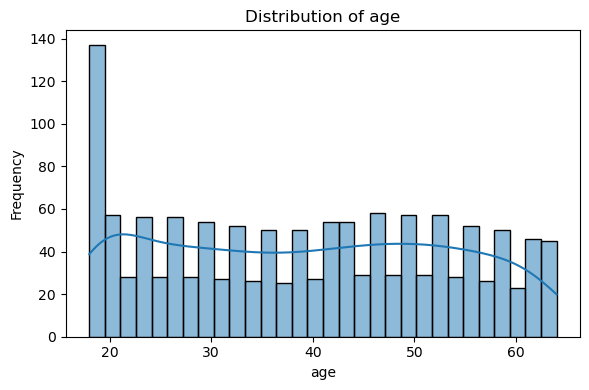

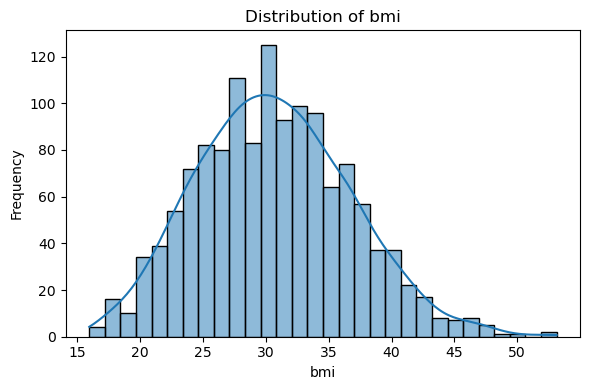

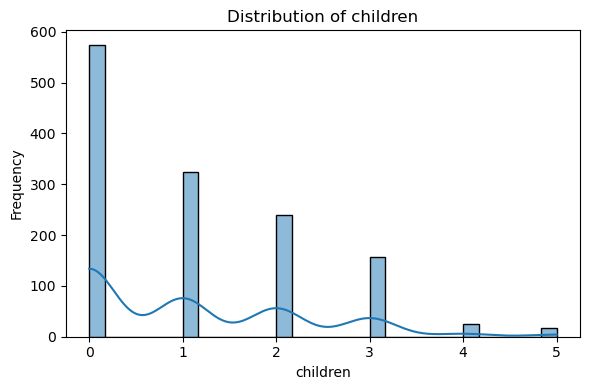

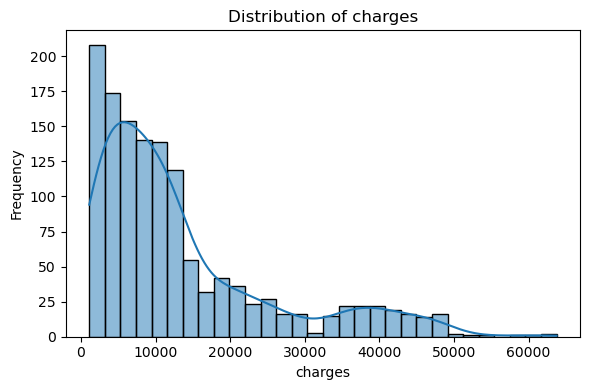

In [8]:
numerical_columns = ['age','bmi','children','charges']
for col in numerical_columns:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col],kde = True , bins = 30)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()


<Axes: xlabel='children', ylabel='count'>

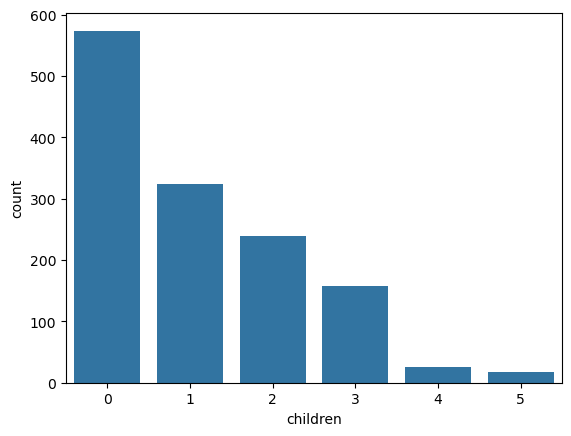

In [9]:
sns.countplot(x = df['children'])

<Axes: xlabel='sex', ylabel='count'>

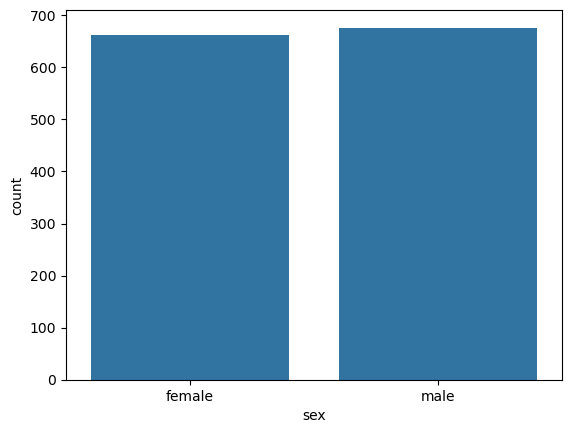

In [10]:
sns.countplot(x = df['sex'])

<Axes: xlabel='smoker', ylabel='count'>

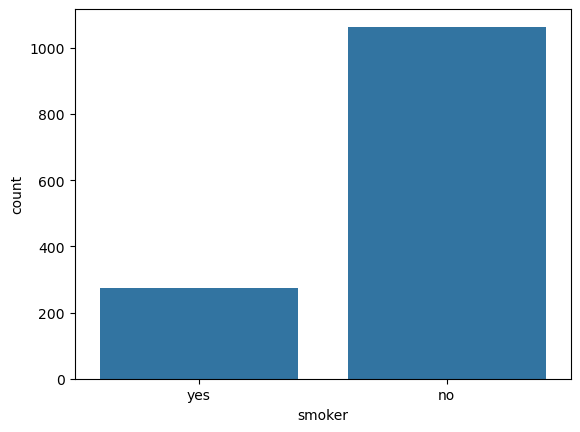

In [11]:
sns.countplot(x = df['smoker'])

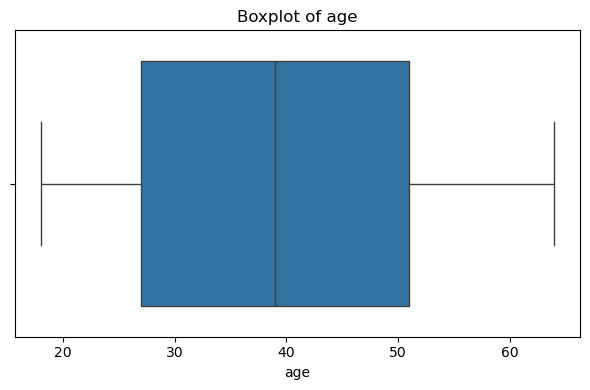

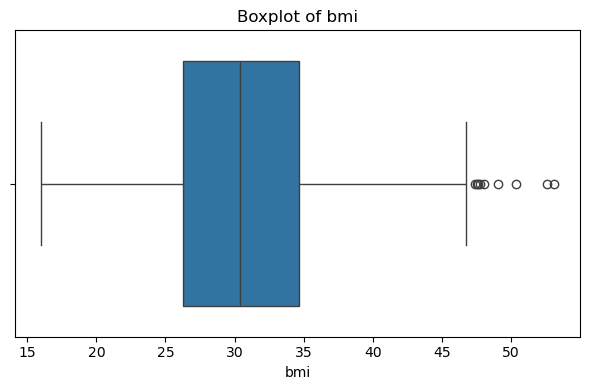

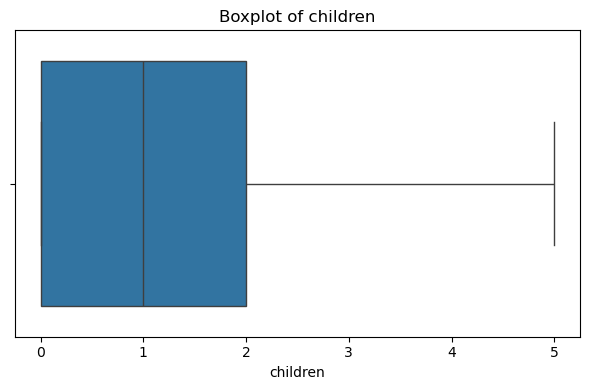

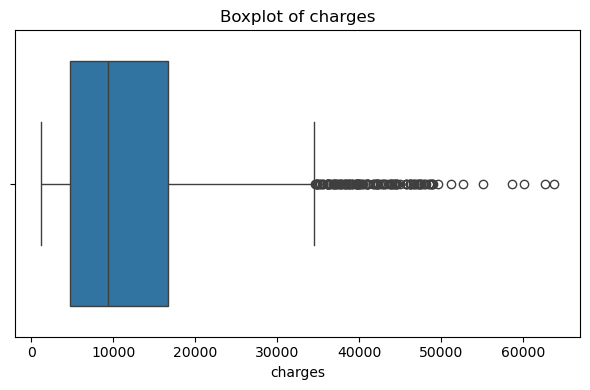

In [12]:
for col in numerical_columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.tight_layout()
    plt.show()

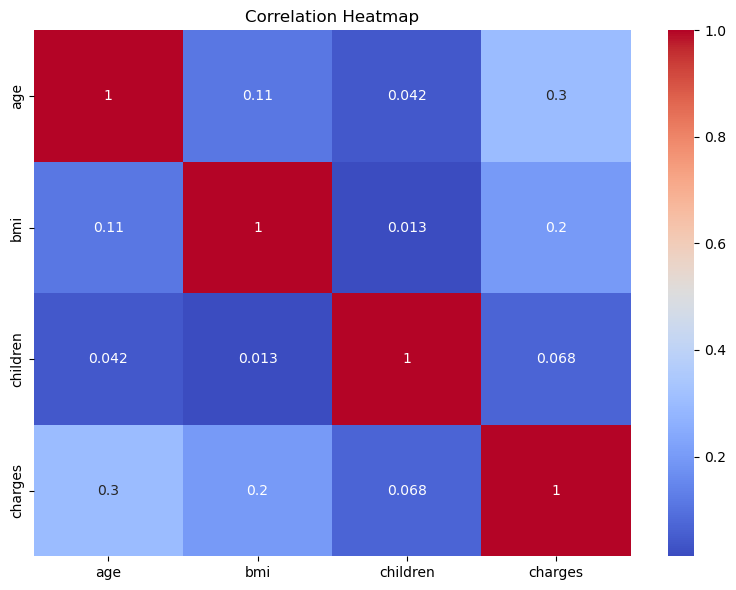

In [13]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

# DATA Cleaning and Preprocessing

In [14]:
df_cleaned = df.copy()


In [15]:
df_cleaned.drop_duplicates(inplace=True)

In [16]:
df_cleaned.shape

(1337, 7)

In [17]:
print("Missing Values:\n", df_cleaned.isnull().sum())

Missing Values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [18]:
print("\nData Types:\n", df_cleaned.dtypes)


Data Types:
 age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [19]:
df_cleaned['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [20]:
df_cleaned['sex'] = df_cleaned['sex'].map({'male': 0, 'female': 1})

In [21]:
df_cleaned['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [22]:
df_cleaned['smoker'] = df_cleaned['smoker'].map({'no': 0, 'yes': 1})

In [23]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [24]:
df_cleaned.rename(columns={
    'sex': 'is_female',
    'smoker': 'is_smoker'
}, inplace=True)

In [25]:
df_cleaned = pd.get_dummies(df_cleaned, columns=['region'], drop_first=True)

In [26]:
df_cleaned = df_cleaned.astype(int)

# Feature Engineering and Extraction

<Axes: xlabel='bmi', ylabel='Count'>

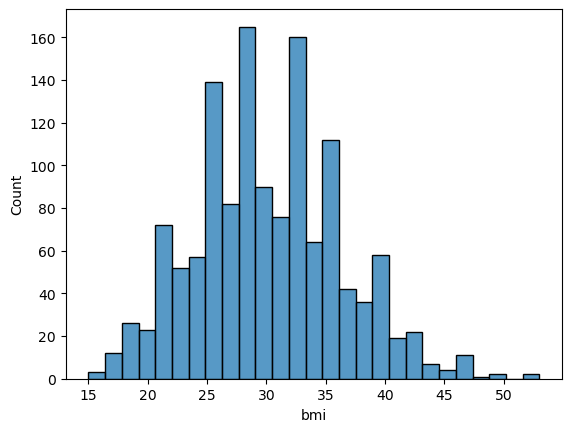

In [27]:
sns.histplot(df_cleaned['bmi'])

In [28]:
df_cleaned['bmi_category'] = pd.cut(
    df_cleaned['bmi'],
    bins=[0, 18.5, 24.9, 29.9, float('inf')],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese']
)

In [29]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27,0,1,16884,0,0,1,Overweight
1,18,0,33,1,0,1725,0,1,0,Obese
2,28,0,33,3,0,4449,0,1,0,Obese
3,33,0,22,0,0,21984,1,0,0,Normal
4,32,0,28,0,0,3866,1,0,0,Overweight
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,1,0,0,Obese
1334,18,1,31,0,0,2205,0,0,0,Obese
1335,18,1,36,0,0,1629,0,1,0,Obese
1336,21,1,25,0,0,2007,0,0,1,Overweight


In [30]:
df_cleaned = pd.get_dummies(df_cleaned, columns=['bmi_category'], drop_first=True)

In [31]:
df_cleaned = df_cleaned.astype(int)

You should scale when you are using ML models that are sensitive to the magnitude of features:

Model Type	Requires Scaling?
Logistic Regression	✅ Yes
Linear Regression	✅ Yes
KNN (K-Nearest Neighbors)	✅ Yes
SVM (Support Vector Machine)	✅ Yes
PCA	✅ Yes
Neural Networks	✅ Yes

❌ Scaling not required for:

Model Type	Why?
Decision Trees	Based on splits, not distances
Random Forest	Same — tree-based
XGBoost / LightGBM	Internally handles scaling

In [32]:
df_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'],
      dtype='object')

In [33]:
from sklearn.preprocessing import StandardScaler
cols_to_scale = ['age', 'bmi', 'children']
scaler = StandardScaler()
df_cleaned[cols_to_scale] = scaler.fit_transform(df_cleaned[cols_to_scale])


In [34]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,1,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,1,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,1,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,1,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,1,0,0,0,1,0


In [35]:

from scipy.stats import pearsonr

# ----------------------------------
# Pearson Correlation Calculation
# ----------------------------------

# List of features to check against target
selected_features = [
    'age', 'bmi', 'children', 'is_female', 'is_smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'
]

# Calculate Pearson correlation
correlations = {
    feature: pearsonr(df_cleaned[feature], df_cleaned['charges'])[0]
    for feature in selected_features
}

# Convert to DataFrame for display
correlation_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Pearson Correlation'])

# Show the results
correlation_df.sort_values(by='Pearson Correlation', ascending=False)


,Feature,Pearson Correlation
4,is_smoker,0.787234
0,age,0.298309
10,bmi_category_Obese,0.200348
1,bmi,0.196236
6,region_southeast,0.073577
2,children,0.067390
5,region_northwest,-0.038695
7,region_southwest,-0.043637
3,is_female,-0.058046
8,bmi_category_Normal,-0.104042


In [36]:
cat_features = [
    'is_female', 'is_smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'
]

In [37]:
from scipy.stats import chi2_contingency
import pandas as pd

# Define significance level
alpha = 0.05

# Bin the target variable
df_cleaned['charges_bin'] = pd.qcut(df_cleaned['charges'], q=4, labels=False)

# Run Chi-Square test
chi2_results = {}

for col in cat_features:
    contingency = pd.crosstab(df_cleaned[col], df_cleaned['charges_bin'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }

# Convert to DataFrame
chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')
chi2_df


,chi2_statistic,p_value,Decision
is_smoker,848.219178,0.0,Reject Null (Keep Feature)
region_southeast,15.998167,0.001135,Reject Null (Keep Feature)
is_female,10.258784,0.01649,Reject Null (Keep Feature)
bmi_category_Obese,8.515711,0.036473,Reject Null (Keep Feature)
region_southwest,5.091893,0.165191,Accept Null (Drop Feature)
bmi_category_Overweight,4.25149,0.235557,Accept Null (Drop Feature)
bmi_category_Normal,3.708088,0.29476,Accept Null (Drop Feature)
region_northwest,1.13424,0.768815,Accept Null (Drop Feature)


In [38]:
df_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese',
       'charges_bin'],
      dtype='object')

In [39]:
final_df = df_cleaned[['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges','region_southeast','bmi_category_Obese','region_northwest']]

In [40]:
final_df

,age,is_female,bmi,children,is_smoker,charges,region_southeast,bmi_category_Obese,region_northwest
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0
1,-1.511647,0,0.462463,-0.079442,0,1725,1,1,0
2,-0.799350,0,0.462463,1.580143,0,4449,1,1,0
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,0,1
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,0,1
...,...,...,...,...,...,...,...,...,...
1333,0.767704,0,-0.027743,1.580143,0,10600,0,1,1
1334,-1.511647,1,0.135659,-0.909234,0,2205,0,1,0
1335,-1.511647,1,0.952670,-0.909234,0,1629,1,1,0
1336,-1.297958,1,-0.844753,-0.909234,0,2007,0,0,0


In [41]:
from sklearn.model_selection import train_test_split


In [42]:
X = final_df.drop('charges', axis=1)
y = final_df['charges']

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [44]:
from sklearn.linear_model import LinearRegression

In [45]:
model = LinearRegression()
model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [46]:
y_pred = model.predict(X_test)

In [47]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test,y_pred)
r2
n = X_test.shape[0]
p = X_test.shape[1]
adjusted_r2 = 1 - ((1- r2) * (n-1) / (n - p - 1))
adjusted_r2

0.7979609952867804

# ------------------------------------------------------------------------------------
## 🏆 MULTIPLE REGRESSION, REGULARIZATION (RIDGE, LASSO, ELASTICNET) & INTERVIEW MASTERY
### Topics Covered:
1. **Multiple Linear Regression Metrics**: MAE, MSE, RMSE, $R^2$, and **Adjusted $R^2$**
2. **The 5 Core Assumptions of Linear Regression & Diagnostic Plots** (Residuals, Q-Q, Homoscedasticity, VIF, Durbin-Watson)
3. **Polynomial Regression**: Modeling non-linear interactions & bias-variance tradeoff
4. **Ridge Regression ($L_2$ Regularization)**: Shrinkage penalty, `RidgeCV`, handling multicollinearity
5. **Lasso Regression ($L_1$ Regularization)**: Sparsity penalty, `LassoCV`, automatic feature selection
6. **ElasticNet Regression ($L_1 + L_2$ Hybrid)**: Correlated group selection, `ElasticNetCV`
7. **Comparative Model Performance Table & Coefficient Path Visualizations**
8. **Top 15 High-Yield Interview Questions & Answers on Regression & Regularization**
# ------------------------------------------------------------------------------------

### 1. Complete Multiple Linear Regression Evaluation: MAE, MSE, RMSE, $R^2$ & Adjusted $R^2$
- **Mean Absolute Error (MAE)**: $\frac{1}{n} \sum |y_i - \hat{y}_i|$ (interpretable in original currency units, robust to outliers).
- **Mean Squared Error (MSE)**: $\frac{1}{n} \sum (y_i - \hat{y}_i)^2$ (penalizes large errors heavily).
- **Root Mean Squared Error (RMSE)**: $\sqrt{\text{MSE}}$ (same units as target, standard industry metric).
- **Coefficient of Determination ($R^2$)**: $1 - \frac{\text{SS}_{\text{res}}}{\text{SS}_{\text{tot}}}$ (proportion of variance explained).
- **Adjusted $R^2$**: $1 - \frac{(1 - R^2)(n - 1)}{n - p - 1}$ where $n$ is sample size and $p$ is number of predictors.
  - *Crucial Interview Concept*: Adding irrelevant features **always** increases or leaves $R^2$ unchanged. Adjusted $R^2$ **penalizes** adding non-informative predictors!

In [48]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate all metrics for Multiple Linear Regression
mae_lr = mean_absolute_error(y_test, y_pred)
mse_lr = mean_squared_error(y_test, y_pred)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred)

n = len(y_test)
p = X_test.shape[1]
adj_r2_lr = 1 - ((1 - r2_lr) * (n - 1) / (n - p - 1))

print(f"=== MULTIPLE LINEAR REGRESSION METRICS ===")
print(f"MAE:         ${mae_lr:,.2f}")
print(f"MSE:         {mse_lr:,.2f}")
print(f"RMSE:        ${rmse_lr:,.2f}")
print(f"R2 Score:    {r2_lr:.4f} ({r2_lr*100:.2f}% variance explained)")
print(f"Adjusted R2: {adj_r2_lr:.4f}")

=== MULTIPLE LINEAR REGRESSION METRICS ===
MAE:         $4,296.48
MSE:         36,013,510.13
RMSE:        $6,001.13
R2 Score:    0.8040 (80.40% variance explained)
Adjusted R2: 0.7980


### 2. Diagnostic Testing of Linear Regression Assumptions
Linear regression relies on 5 fundamental Gauss-Markov assumptions:
1. **Linearity**: The relationship between $X$ and $Y$ is linear (Residuals vs Fitted plot).
2. **Homoscedasticity**: Constant residual variance across predictions (no funnel shape).
3. **Normality of Residuals**: Errors are normally distributed $\epsilon \sim \mathcal{N}(0, \sigma^2)$ (Q-Q plot).
4. **Independence of Errors**: No autocorrelation between residuals (Durbin-Watson test).
5. **No Multicollinearity**: Predictors are not linearly dependent (VIF < 5).

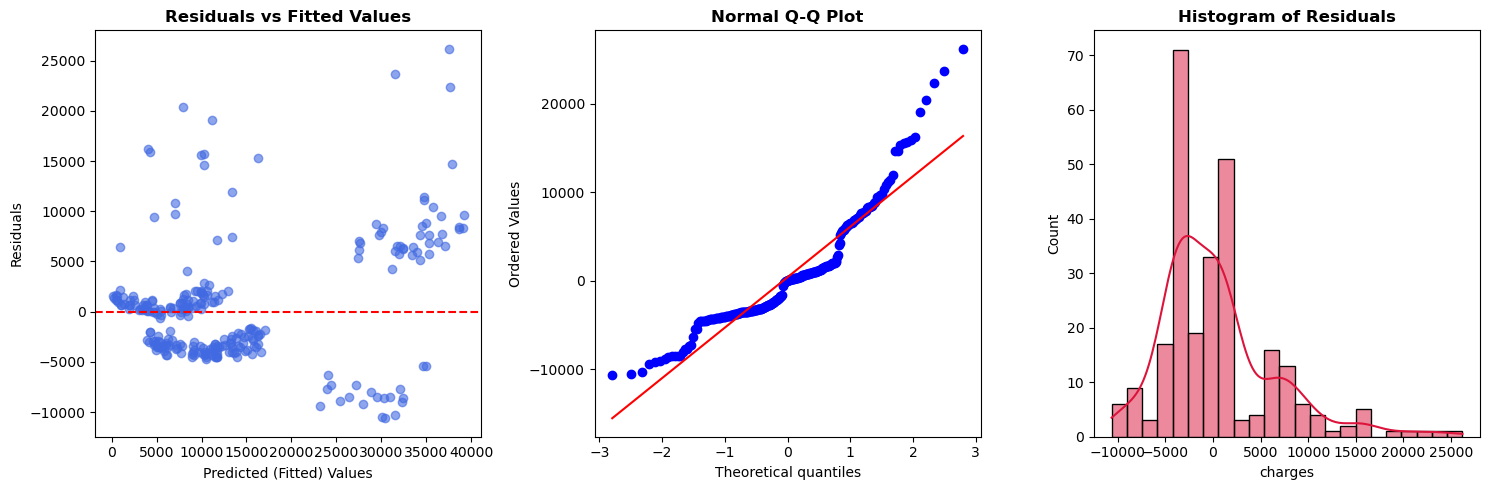

Durbin-Watson Statistic: 2.061 (Values ~2 indicate zero autocorrelation)


In [49]:
from scipy import stats
from statsmodels.stats.stattools import durbin_watson

residuals = y_test - y_pred

plt.figure(figsize=(15, 5))
# 1. Residuals vs Fitted (Checks Linearity & Homoscedasticity)
plt.subplot(1, 3, 1)
plt.scatter(y_pred, residuals, alpha=0.6, color='royalblue')
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals vs Fitted Values', fontweight='bold')
plt.xlabel('Predicted (Fitted) Values')
plt.ylabel('Residuals')

# 2. Q-Q Plot (Checks Normality of Errors)
plt.subplot(1, 3, 2)
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('Normal Q-Q Plot', fontweight='bold')

# 3. Residual Distribution
plt.subplot(1, 3, 3)
sns.histplot(residuals, kde=True, color='crimson')
plt.title('Histogram of Residuals', fontweight='bold')
plt.tight_layout()
plt.show()

dw_stat = durbin_watson(residuals)
print(f"Durbin-Watson Statistic: {dw_stat:.3f} (Values ~2 indicate zero autocorrelation)")

### 3. Polynomial Regression: Capturing Non-Linear Curvatures
When relationships are non-linear, polynomial features ($X^2, X_1 X_2$) allow linear models to fit complex curvatures.

In [50]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)
y_pred_poly = poly_model.predict(X_test_poly)

r2_poly = r2_score(y_test, y_pred_poly)
rmse_poly = np.sqrt(mean_squared_error(y_test, y_pred_poly))
adj_r2_poly = 1 - ((1 - r2_poly) * (n - 1) / (n - X_test_poly.shape[1] - 1))

print(f"Polynomial Degree 2 Model:")
print(f"Original Linear Model R2:     {r2_lr:.4f}  |  RMSE: ${rmse_lr:,.2f}")
print(f"Polynomial Degree 2 Model R2: {r2_poly:.4f}  |  RMSE: ${rmse_poly:,.2f}")
print(f"Features expanded from {X_train.shape[1]} to {X_train_poly.shape[1]}")

Polynomial Degree 2 Model:
Original Linear Model R2:     0.8040  |  RMSE: $6,001.13
Polynomial Degree 2 Model R2: 0.9023  |  RMSE: $4,236.88
Features expanded from 8 to 44


### 4. Ridge Regression ($L_2$ Regularization)
#### Mathematical Formulation:
$$\mathcal{L}_{\text{Ridge}}(w) = \frac{1}{2n} \sum_{i=1}^n (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^p w_j^2$$
- **Closed-Form Solution**: $w = (X^T X + \alpha I)^{-1} X^T y$
- **Key Mechanism**: Adds $\alpha$ to the diagonal of $X^T X$, making it strictly invertible even if severe multicollinearity exists.
- **Shrinkage Effect**: Smoothly shrinks all weights towards zero, reducing variance without setting coefficients to absolute zero.

In [51]:
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.preprocessing import StandardScaler

# Standardize features before applying regularization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Find optimal alpha via 5-Fold Cross Validation
alphas = np.logspace(-3, 4, 100)
ridge_cv = RidgeCV(alphas=alphas, cv=5)
ridge_cv.fit(X_train_scaled, y_train)

best_alpha_ridge = ridge_cv.alpha_
y_pred_ridge = ridge_cv.predict(X_test_scaled)

r2_ridge = r2_score(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
adj_r2_ridge = 1 - ((1 - r2_ridge) * (n - 1) / (n - p - 1))

print(f"=== RIDGE REGRESSION ($L_2$) ===")
print(f"Optimal Alpha ($\alpha$): {best_alpha_ridge:.3f}")
print(f"R2 Score:               {r2_ridge:.4f}")
print(f"Adjusted R2:            {adj_r2_ridge:.4f}")
print(f"RMSE:                   ${rmse_ridge:,.2f}")

=== RIDGE REGRESSION ($L_2$) ===
Optimal Alpha ($lpha$): 10.723
R2 Score:               0.8022
Adjusted R2:            0.7961
RMSE:                   $6,029.27


### 5. Lasso Regression ($L_1$ Regularization)
#### Mathematical Formulation:
$$\mathcal{L}_{\text{Lasso}}(w) = \frac{1}{2n} \sum_{i=1}^n (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^p |w_j|$$
- **Key Mechanism**: The $L_1$ norm creates sharp, non-differentiable corners along coordinate axes.
- **Sparsity & Feature Selection**: As $\alpha$ increases, unimportant features have their coefficients driven to **exact zero**!

In [52]:
from sklearn.linear_model import Lasso, LassoCV

lasso_cv = LassoCV(alphas=np.logspace(-2, 3, 100), cv=5, random_state=42)
lasso_cv.fit(X_train_scaled, y_train)

best_alpha_lasso = lasso_cv.alpha_
y_pred_lasso = lasso_cv.predict(X_test_scaled)

r2_lasso = r2_score(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
adj_r2_lasso = 1 - ((1 - r2_lasso) * (n - 1) / (n - p - 1))

print(f"=== LASSO REGRESSION ($L_1$) ===")
print(f"Optimal Alpha ($\alpha$): {best_alpha_lasso:.3f}")
print(f"R2 Score:               {r2_lasso:.4f}")
print(f"Adjusted R2:            {adj_r2_lasso:.4f}")
print(f"RMSE:                   ${rmse_lasso:,.2f}")

# Display features with non-zero vs zero coefficients
lasso_coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Lasso_Coefficient': lasso_cv.coef_
})
print("\nLasso Learned Coefficients:")
display(lasso_coef_df)

=== LASSO REGRESSION ($L_1$) ===
Optimal Alpha ($lpha$): 77.426
R2 Score:               0.8015
Adjusted R2:            0.7953
RMSE:                   $6,039.87

Lasso Learned Coefficients:


,Feature,Lasso_Coefficient
0,age,3416.029585
1,is_female,0.000000
2,bmi,480.226776
3,children,570.320310
4,is_smoker,9143.217300
5,region_southeast,-9.388493
6,bmi_category_Obese,1615.509338
7,region_northwest,0.000000


### 6. ElasticNet Regression ($L_1 + L_2$ Hybrid Regularization)
#### Mathematical Formulation:
$$\mathcal{L}_{\text{ElasticNet}}(w) = \text{MSE} + \alpha \left[ \rho \sum_{j=1}^p |w_j| + \frac{1 - \rho}{2} \sum_{j=1}^p w_j^2 \right]$$
where $\rho = \text{l1\_ratio} \in [0, 1]$.
- If $\rho = 1$, ElasticNet becomes pure Lasso.
- If $\rho = 0$, ElasticNet becomes pure Ridge.
- **The Correlated Feature Solution**: If features $A$ and $B$ are strongly correlated, Lasso arbitrarily picks one and zeroes out the other. ElasticNet groups them and shrinks them together!

In [53]:
from sklearn.linear_model import ElasticNet, ElasticNetCV

l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]
elastic_cv = ElasticNetCV(alphas=np.logspace(-3, 3, 50), l1_ratio=l1_ratios, cv=5, random_state=42)
elastic_cv.fit(X_train_scaled, y_train)

best_alpha_elastic = elastic_cv.alpha_
best_l1_ratio = elastic_cv.l1_ratio_
y_pred_elastic = elastic_cv.predict(X_test_scaled)

r2_elastic = r2_score(y_test, y_pred_elastic)
rmse_elastic = np.sqrt(mean_squared_error(y_test, y_pred_elastic))
adj_r2_elastic = 1 - ((1 - r2_elastic) * (n - 1) / (n - p - 1))

print(f"=== ELASTICNET REGRESSION ($L_1 + L_2$) ===")
print(f"Optimal Alpha:    {best_alpha_elastic:.3f}")
print(f"Optimal L1-Ratio: {best_l1_ratio:.2f}")
print(f"R2 Score:         {r2_elastic:.4f}")
print(f"Adjusted R2:      {adj_r2_elastic:.4f}")
print(f"RMSE:             ${rmse_elastic:,.2f}")

=== ELASTICNET REGRESSION ($L_1 + L_2$) ===
Optimal Alpha:    0.869
Optimal L1-Ratio: 0.99
R2 Score:         0.8024
Adjusted R2:      0.7963
RMSE:             $6,025.79


### 7. Comprehensive Model Benchmark & Coefficient Comparison
Visualizing the learned weights across Linear, Ridge, Lasso, and ElasticNet models.

=== REGRESSION BENCHMARK COMPARISON ===


,Model,R2 Score,Adjusted R2,RMSE,MAE
0,Multiple Linear,0.804015,0.797961,6001.125739,4296.477797
1,Ridge (L2),0.802172,0.796061,6029.271425,4309.718443
2,Lasso (L1),0.801476,0.795344,6039.871938,4286.756056
3,ElasticNet (L1+L2),0.802400,0.796297,6025.787416,4307.618514
4,Polynomial (Deg 2),0.902310,0.883035,4236.881461,2362.753789


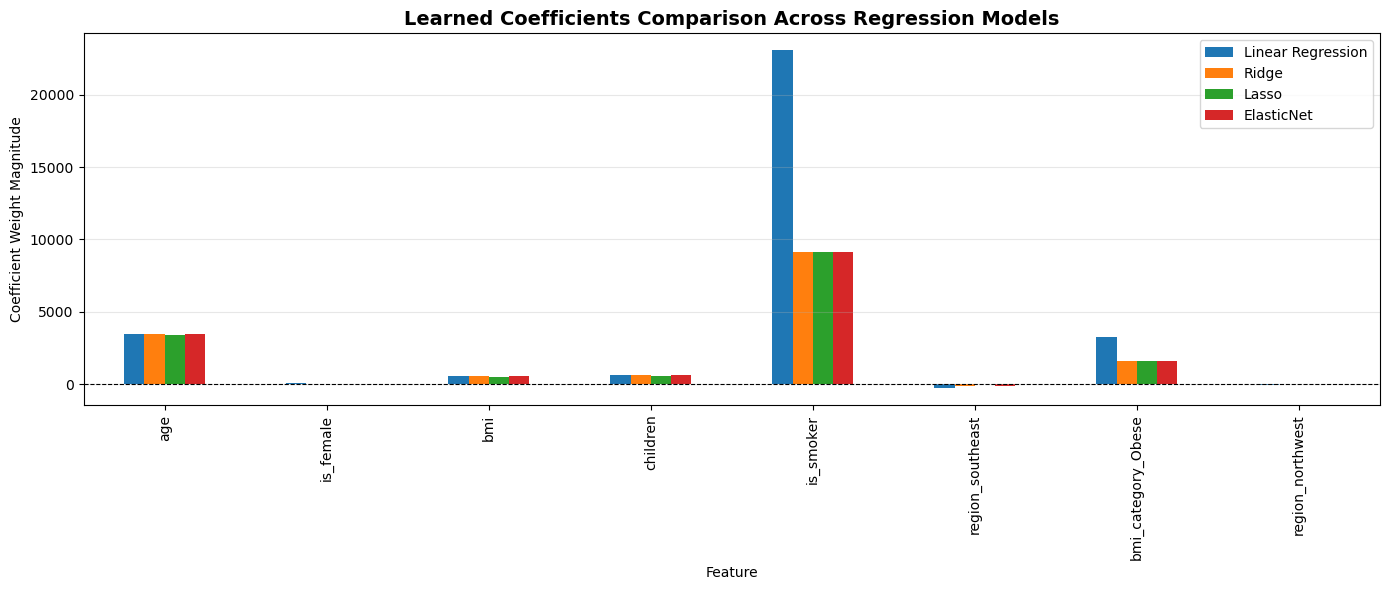

In [54]:
# Benchmark summary table
benchmark_df = pd.DataFrame({
    'Model': ['Multiple Linear', 'Ridge (L2)', 'Lasso (L1)', 'ElasticNet (L1+L2)', 'Polynomial (Deg 2)'],
    'R2 Score': [r2_lr, r2_ridge, r2_lasso, r2_elastic, r2_poly],
    'Adjusted R2': [adj_r2_lr, adj_r2_ridge, adj_r2_lasso, adj_r2_elastic, adj_r2_poly],
    'RMSE': [rmse_lr, rmse_ridge, rmse_lasso, rmse_elastic, rmse_poly],
    'MAE': [mae_lr, mean_absolute_error(y_test, y_pred_ridge), mean_absolute_error(y_test, y_pred_lasso), mean_absolute_error(y_test, y_pred_elastic), mean_absolute_error(y_test, y_pred_poly)]
})
print("=== REGRESSION BENCHMARK COMPARISON ===")
display(benchmark_df)

# Coefficients comparison plot
coef_comparison = pd.DataFrame({
    'Feature': X.columns,
    'Linear Regression': model.coef_,
    'Ridge': ridge_cv.coef_,
    'Lasso': lasso_cv.coef_,
    'ElasticNet': elastic_cv.coef_
}).set_index('Feature')

coef_comparison.plot(kind='bar', figsize=(14, 6))
plt.title('Learned Coefficients Comparison Across Regression Models', fontsize=14, fontweight='bold')
plt.ylabel('Coefficient Weight Magnitude')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 8. Regularization Path Visualization
Plotting how coefficients shrink as the regularization parameter $\alpha$ increases from $10^{-3}$ to $10^{4}$ for both Ridge and Lasso.

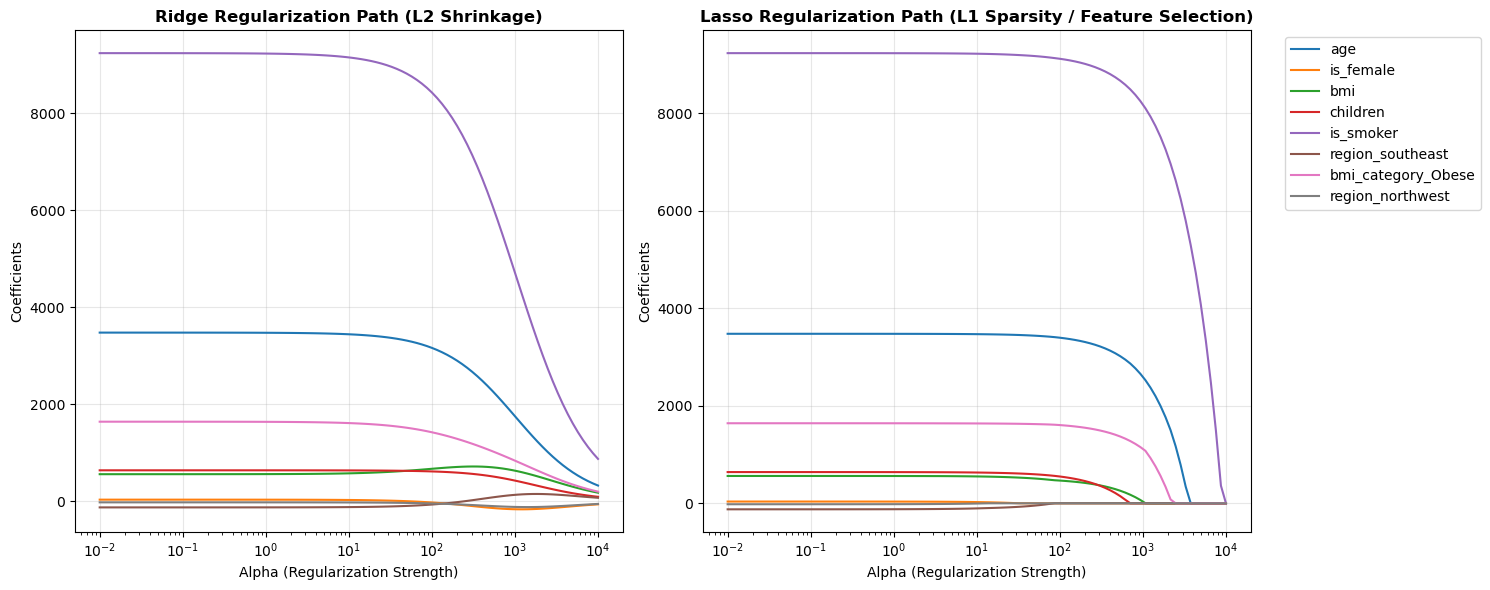

In [55]:
alphas_range = np.logspace(-2, 4, 100)
ridge_coef_path = []
lasso_coef_path = []

for a in alphas_range:
    r = Ridge(alpha=a).fit(X_train_scaled, y_train)
    l = Lasso(alpha=a, max_iter=2000, random_state=42).fit(X_train_scaled, y_train)
    ridge_coef_path.append(r.coef_)
    lasso_coef_path.append(l.coef_)

ridge_coef_path = np.array(ridge_coef_path)
lasso_coef_path = np.array(lasso_coef_path)

plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 1)
for i in range(X.shape[1]):
    plt.plot(alphas_range, ridge_coef_path[:, i], label=X.columns[i])
plt.xscale('log')
plt.title('Ridge Regularization Path (L2 Shrinkage)', fontweight='bold')
plt.xlabel('Alpha (Regularization Strength)')
plt.ylabel('Coefficients')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
for i in range(X.shape[1]):
    plt.plot(alphas_range, lasso_coef_path[:, i], label=X.columns[i])
plt.xscale('log')
plt.title('Lasso Regularization Path (L1 Sparsity / Feature Selection)', fontweight='bold')
plt.xlabel('Alpha (Regularization Strength)')
plt.ylabel('Coefficients')
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 9. Top 15 Machine Learning Interview Questions: Regression & Regularization

| # | Question | Comprehensive Interview-Grade Answer |
|---|---|---|
| **1** | **Why does $R^2$ always increase when adding features, and how does Adjusted $R^2$ solve this?** | $R^2 = 1 - \frac{\text{SS}_{\text{res}}}{\text{SS}_{\text{tot}}}$. Adding any predictor allows OLS to capture at least incidental noise in the sample, which can never increase $\text{SS}_{\text{res}}$. Adjusted $R^2 = 1 - \frac{(1 - R^2)(n - 1)}{n - p - 1}$ divides by degrees of freedom; if the new feature does not reduce error by more than what is expected by chance, Adjusted $R^2$ decreases. |
| **2** | **Why does Lasso ($L_1$) lead to exact zero coefficients (sparsity) while Ridge ($L_2$) does not?** | Geometrically, the $L_1$ constraint $|w_1| + |w_2| \le t$ forms a diamond (polytope) with sharp corners located on the axes where coordinates equal zero. The elliptical contours of the MSE loss function are mathematically far more likely to intersect the constraint region at one of these corners. In contrast, the $L_2$ constraint $w_1^2 + w_2^2 \le t^2$ is a smooth hypersphere (circle) with no sharp corners, so intersection almost never occurs at exact zero. |
| **3** | **Why MUST features be scaled before applying Ridge or Lasso?** | The penalty term $\alpha \sum w_j^2$ or $\alpha \sum |w_j|$ treats all weights equally. If feature $A$ has units of millimeters ($x \sim 1000$) and feature $B$ has units of meters ($x \sim 1$), the model naturally assigns a tiny coefficient to $A$ and large coefficient to $B$. The regularization penalty will heavily penalize $B$ simply due to its measurement scale! Scaling ensures uniform regularization. |
| **4** | **When would you prefer ElasticNet over Lasso?** | When features are highly correlated with each other (multicollinearity). Lasso arbitrarily selects one correlated feature and zeroes out the others, leading to erratic feature selection. ElasticNet groups correlated features together and shrinks them jointly due to the strictly convex $L_2$ term. |
| **5** | **What is the closed-form OLS solution and when does it fail?** | $w = (X^T X)^{-1} X^T y$. It fails when $X^T X$ is singular (non-invertible). This occurs when: (1) Features are collinear (determinant is 0), or (2) $p > n$ (more features than training examples). Ridge solves this because $(X^T X + \alpha I)$ is always strictly positive definite and invertible. |
| **6** | **What is Heteroscedasticity and why is it a problem in OLS?** | Heteroscedasticity means the variance of residuals is not constant across fitted values $\text{Var}(\epsilon_i) \ne \sigma^2$. While OLS point estimates remain unbiased, their standard errors and p-values become invalid, rendering hypothesis tests (t-tests, F-tests) untrustworthy. Solution: Log transform target, Weighted Least Squares (WLS), or Huber-White robust standard errors. |
| **7** | **What is the Bias-Variance tradeoff in Regularization?** | As $\alpha \to 0$, model has low bias and high variance (risk of overfitting). As $\alpha \to \infty$, coefficients shrink towards zero, introducing slight bias but drastically decreasing variance (error from sensitivity to training noise), optimizing total generalization error $\text{MSE} = \text{Bias}^2 + \text{Variance} + \sigma^2$. |
| **8** | **Can Ridge Regression perform feature selection?** | No. In Ridge, coefficients approach zero asymptotically as $\alpha \to \infty$, but mathematically they never reach exact zero because the gradient is proportional to $w$ and vanishes at $w = 0$. |
| **9** | **How does the Durbin-Watson statistic detect autocorrelation?** | $\text{DW} = \frac{\sum_{t=2}^T (e_t - e_{t-1})^2}{\sum_{t=1}^T e_t^2}$. $\text{DW} \approx 2$ indicates zero autocorrelation. $\text{DW} < 2$ indicates positive serial correlation; $\text{DW} > 2$ indicates negative serial correlation. Autocorrelation violates independence of errors. |
| **10** | **Why do we never regularize the intercept term $\beta_0$?** | The intercept represents the expected mean value of $Y$ when all centered predictors are zero. Penalizing the intercept would force the prediction baseline towards zero, biasing the mean of predictions away from the true mean of the target. |
| **11** | **What is Cook's Distance in regression?** | Cook's distance measures the influence of a single data point on all fitted values. A point with high leverage and high residual disproportionately pulls the regression line. Points with $D_i > 4/n$ or $D_i > 1$ are considered influential outliers. |
| **12** | **What is the difference between R2 and Pearson correlation squared?** | In Simple Linear Regression with an intercept, $R^2 = r_{xy}^2$. In Multiple Regression, $R^2 = r_{y, \hat{y}}^2$ (the squared correlation between true values and predictions). If evaluated on test data without refitting, $R^2$ can even be negative (meaning predictions are worse than simply predicting the mean). |
| **13** | **What are the Gauss-Markov theorem conditions?** | Under the assumptions of linearity, strict exogeneity $E[\epsilon|X] = 0$, homoscedasticity, and no autocorrelation, the OLS estimator is **BLUE**: **B**est **L**inear **U**nbiased **E**stimator (minimum variance among all linear unbiased estimators). |
| **14** | **What is Stochastic Gradient Descent (SGD) for Linear Regression?** | For massive datasets where computing $(X^T X)^{-1}$ ($O(p^3)$ time, $O(np)$ memory) is infeasible, SGD updates weights incrementally per sample/batch using $w \leftarrow w - \eta \nabla \mathcal{L}$, enabling online streaming regression with constant memory. |
| **15** | **How do you choose between MAE, MSE, and RMSE for business metrics?** | Use **MAE** when business cost is linearly proportional to error and outliers should not dominate (e.g. median wait times). Use **RMSE/MSE** when large errors are catastrophically worse than small errors (e.g. inventory shortages or power grid load forecasting). |